# DenseNet121 phân loại X-quang ngực: COVID-19 vs Normal

- Dữ liệu: `dacntt-kltn/covid-normal-cxr` (train / validation / test), nhãn `normal=0`, `covid19=1`
- Mô hình: DenseNet121 pretrained ImageNet
- **Early stopping** theo tập val, **checkpoint đẩy lên Hugging Face** (đồng bộ nền + lần cuối)
- Đánh giá trên tập **test** bằng checkpoint tốt nhất theo val

## 1. Import

In [1]:
import os, re, json, time, random, shutil, threading
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1" #tắt thông báo tải data
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision.transforms as T
from torch.utils.data import DataLoader
from torchvision.models import densenet121, DenseNet121_Weights

from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

from datasets import load_dataset
from huggingface_hub import login, HfApi, create_repo, list_repo_files, hf_hub_download
from kaggle_secrets import UserSecretsClient

## 2. Cấu hình

In [ ]:
# Hugging Face
HF_USERNAME = "dacntt-kltn"
DATASET_REPO_ID = f"{HF_USERNAME}/covid-normal-cxr"
MODEL_REPO_ID = f"{HF_USERNAME}/densenet121-covid-normal-cxr"
MODEL_PRIVATE = False 
RUNS_PREFIX = "training-runs"

# Tham số huấn luyện 
SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
LR = 1e-4
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 100
LR_PATIENCE = 2 

# Early stopping
MONITOR = "val_loss" # chỉ số theo dõi để dừng
PATIENCE = 10       
MIN_DELTA = 1e-4 # mức cải thiện tối thiểu
MODE = "min" if MONITOR == "val_loss" else "max"

# Đồng bộ lên Hub
RESUME_FROM_HUB = False # True: nếu run mới nhất trên Hub chưa xong thì train tiếp
SYNC_INTERVAL_SEC = 300 # đẩy checkpoint lên Hub mỗi 5 phút 

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device, "| AMP:", use_amp)

device: cuda | AMP: True


## 3. Đăng nhập Hugging Face và tạo repo model

In [3]:
token = UserSecretsClient().get_secret("HF_TOKEN")
login(token=token)

api = HfApi()
print("Đăng nhập là:", api.whoami()["name"])
create_repo(MODEL_REPO_ID, repo_type="model", private=MODEL_PRIVATE, exist_ok=True)
print(f"Model repo: https://huggingface.co/{MODEL_REPO_ID}")
print(f"Dataset repo: https://huggingface.co/datasets/{DATASET_REPO_ID}")

Đăng nhập là: lpv30
Model repo: https://huggingface.co/dacntt-kltn/densenet121-covid-normal-cxr
Dataset repo: https://huggingface.co/datasets/dacntt-kltn/covid-normal-cxr


## 4. Tải dữ liệu từ Hugging Face

In [4]:
ds = load_dataset(DATASET_REPO_ID, token=token)
print(ds)

label_names = ds["train"].features["label"].names
print("Nhãn:", label_names)
assert label_names == ["normal", "covid19"], "Thứ tự nhãn không đúng (cần normal=0, covid19=1)"

for split in ds:
    cnt = pd.Series(ds[split]["label"]).value_counts().sort_index()
    print(f"{split:>10}: " + ", ".join(f"{label_names[i]}={n}" for i, n in cnt.items()))

Resolving data files:   0%|          | 0/14507 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3615 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/4535 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/14507 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3615 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/4535 [00:00<?, ?it/s]

Generating train split:   0%|          | 0/14507 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4535 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 14507
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 3615
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 4535
    })
})
Nhãn: ['normal', 'covid19']
     train: normal=6849, covid19=7658
validation: normal=1712, covid19=1903
      test: normal=2140, covid19=2395


## 5. Tiền xử lý và DataLoader

Ảnh gốc là xám 1 kênh 256×256; DenseNet pretrained cần 3 kênh nên nhân ra 3.
Augmentation nhẹ (xoay/dịch/zoom nhỏ), **không lật ngang** 

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet

train_tf = T.Compose([
    T.Grayscale(3),
    T.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Grayscale(3), T.ToTensor(), T.Normalize(MEAN, STD)])

def make_fn(tf):
    def fn(batch):
        return {"pixel_values": [tf(im) for im in batch["image"]], "label": batch["label"]}
    return fn

def collate(batch):
    x = torch.stack([b["pixel_values"] for b in batch])
    y = torch.tensor([b["label"] for b in batch], dtype=torch.float32)
    return x, y

g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(ds["train"].with_transform(make_fn(train_tf)), batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=NUM_WORKERS, collate_fn=collate, pin_memory=True, generator=g)
val_dl = DataLoader(ds["validation"].with_transform(make_fn(eval_tf)), batch_size=64, shuffle=False,
                      num_workers=NUM_WORKERS, collate_fn=collate, pin_memory=True)
test_dl = DataLoader(ds["test"].with_transform(make_fn(eval_tf)), batch_size=64, shuffle=False,
                      num_workers=NUM_WORKERS, collate_fn=collate, pin_memory=True)

x, y = next(iter(train_dl))
print("batch:", x.shape, y.shape, "| nhãn trong batch:", y.int().tolist()[:16])

batch: torch.Size([32, 3, 256, 256]) torch.Size([32]) | nhãn trong batch: [1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1]


## 6. Mô hình và hàm đánh giá

In [12]:
USE_PRETRAINED = False  

def build_model():
    weights = DenseNet121_Weights.IMAGENET1K_V1 if USE_PRETRAINED else None
    m = densenet121(weights=weights)
    m.classifier = nn.Linear(m.classifier.in_features, 1)   # 1 logit: 1 = covid19, 0 = normal
    return m

criterion = nn.BCEWithLogitsLoss()

@torch.no_grad()
def evaluate(model, dl, threshold=0.5):
    model.eval()
    loss_sum, probs, labels = 0.0, [], []
    for x, y in dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x).squeeze(1)
        logits = logits.float()
        loss_sum += criterion(logits, y).item() * len(y)
        probs.append(torch.sigmoid(logits).cpu()); labels.append(y.cpu())
    probs = torch.cat(probs).numpy(); labels = torch.cat(labels).numpy().astype(int)
    pred = (probs >= threshold).astype(int)
    return dict(loss=loss_sum / len(labels), acc=accuracy_score(labels, pred),
                auc=roc_auc_score(labels, probs), f1=f1_score(labels, pred),
                probs=probs, labels=labels, pred=pred)

def atomic_save(obj, path):
    tmp = str(path) + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

## 7. Thư mục run và resume từ Hub

Mỗi lần train là một run: `training-runs/<số 5 chữ số>-densenet121-covid-normal/` gồm `best.pt`, `last.pt`, `history.csv`, ...
Nếu run mới nhất trên Hub có `last.pt` mà chưa có `finished.json` thì train **tiếp run đó** (giữ nguyên trạng thái early stopping); nếu không thì tạo run mới với số thứ tự kế tiếp.

In [14]:
LOCAL_OUTDIR = Path("/kaggle/working/densenet121-training-runs")
LOCAL_OUTDIR.mkdir(parents=True, exist_ok=True)

existing_files = list_repo_files(MODEL_REPO_ID, repo_type="model")
run_re = re.compile(rf"^{RUNS_PREFIX}/([0-9]{{5}}-[^/]+)/(.+)$")
hub_runs = {}
for f in existing_files:
    m = run_re.match(f)
    if m:
        hub_runs.setdefault(m.group(1), set()).add(m.group(2))
print("Các run đã có trên Hub:", sorted(hub_runs))

resume_state, RUN_NAME = None, None
if RESUME_FROM_HUB and hub_runs:
    latest = sorted(hub_runs)[-1]
    if "last.pt" in hub_runs[latest] and "finished.json" not in hub_runs[latest]:
        RUN_NAME = latest
        RUN_DIR = LOCAL_OUTDIR / RUN_NAME
        RUN_DIR.mkdir(parents=True, exist_ok=True)
        for fn in ["last.pt", "best.pt"]:
            if fn in hub_runs[latest]:
                p = hf_hub_download(MODEL_REPO_ID, f"{RUNS_PREFIX}/{latest}/{fn}", repo_type="model")
                shutil.copy(p, RUN_DIR / fn)
        resume_state = torch.load(RUN_DIR / "last.pt", map_location="cpu", weights_only=False) 
        print(f"RESUME run {RUN_NAME} từ epoch {resume_state['state']['epoch']}")

if resume_state is None:
    next_id = int(sorted(hub_runs)[-1][:5]) + 1 if hub_runs else 0
    RUN_NAME = f"{next_id:05d}-densenet121-covid-normal"
    RUN_DIR = LOCAL_OUTDIR / RUN_NAME
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    print("Train từ đầu, run mới:", RUN_NAME)

Các run đã có trên Hub: ['00000-densenet121-covid-normal']
Train từ đầu, run mới: 00001-densenet121-covid-normal-trainfromscratch


## 8. Huấn luyện + early stopping + đồng bộ Hub

- Mỗi epoch: tính val; nếu `MONITOR` cải thiện thì lưu `best.pt`, ngược lại tăng bộ đếm; luôn lưu `last.pt` (model + optimizer + trạng thái early stopping) để resume.
- Luồng nền đẩy thư mục run lên Hub mỗi `SYNC_INTERVAL_SEC` giây nếu có file thay đổi; khối `finally` đẩy lần cuối kể cả khi bị ngắt giữa chừng.

In [ ]:
model = build_model().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode=MODE, factor=0.5, patience=LR_PATIENCE)
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

state = dict(epoch=0, best=None, best_epoch=-1, bad_epochs=0, history=[])
if resume_state is not None:
    model.load_state_dict(resume_state["model"])
    opt.load_state_dict(resume_state["opt"])
    sched.load_state_dict(resume_state["sched"])
    scaler.load_state_dict(resume_state["scaler"])
    state = resume_state["state"]

def is_better(cur, best):
    if best is None: return True
    return cur < best - MIN_DELTA if MODE == "min" else cur > best + MIN_DELTA

# Luồng đồng bộ nền
api_sync = HfApi()
sync_stop = threading.Event()

def upload_run_dir(msg):
    api_sync.upload_folder(folder_path=str(RUN_DIR), repo_id=MODEL_REPO_ID, repo_type="model",
                           path_in_repo=f"{RUNS_PREFIX}/{RUN_NAME}", ignore_patterns=["*.tmp"],
                           commit_message=msg)

def sync_to_hub():
    last_sig = None
    while not sync_stop.wait(SYNC_INTERVAL_SEC):
        try:
            sig = tuple(sorted((p.name, p.stat().st_mtime) for p in RUN_DIR.iterdir()
                               if p.is_file() and p.suffix != ".tmp"))
            if sig and sig != last_sig:
                upload_run_dir(f"sync {RUN_NAME}")
                last_sig = sig
                print("[sync] đã đồng bộ lên Hub.")
        except Exception as e:
            print("[sync] Lỗi khi đồng bộ:", e)

sync_thread = threading.Thread(target=sync_to_hub, daemon=True)
sync_thread.start()

# Vòng lặp huấn luyện
stop_reason = None
try:
    for epoch in range(state["epoch"], MAX_EPOCHS):
        t0 = time.time()
        model.train()
        loss_sum, n = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x).squeeze(1)
            loss = criterion(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            loss_sum += loss.item() * len(y); n += len(y)

        val = evaluate(model, val_dl)
        row = dict(epoch=epoch + 1, train_loss=loss_sum / n, val_loss=val["loss"], val_acc=val["acc"],
                   val_auc=val["auc"], val_f1=val["f1"], lr=opt.param_groups[0]["lr"])
        state["history"].append(row)
        cur = row[MONITOR]
        sched.step(cur)

        if is_better(cur, state["best"]):
            state.update(best=cur, best_epoch=epoch + 1, bad_epochs=0)
            atomic_save(dict(model=model.state_dict(), epoch=epoch + 1, monitor=MONITOR, value=cur,
                             label_names=label_names), RUN_DIR / "best.pt")
            tag = "  <- best"
        else:
            state["bad_epochs"] += 1
            tag = f"  (không cải thiện {state['bad_epochs']}/{PATIENCE})"

        state["epoch"] = epoch + 1
        atomic_save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                         scaler=scaler.state_dict(), state=state), RUN_DIR / "last.pt")
        pd.DataFrame(state["history"]).to_csv(RUN_DIR / "history.csv", index=False)

        print(f"epoch {epoch+1:02d} | train_loss {row['train_loss']:.4f} | val_loss {row['val_loss']:.4f} | "
              f"val_acc {row['val_acc']:.4f} | val_auc {row['val_auc']:.4f} | lr {row['lr']:.1e} | "
              f"{time.time()-t0:.0f}s{tag}")

        if state["bad_epochs"] >= PATIENCE:
            stop_reason = "early_stopping"
            print(f"Early stopping: {MONITOR} không cải thiện sau {PATIENCE} epoch. Tốt nhất ở epoch {state['best_epoch']}.")
            break
    else:
        stop_reason = "max_epochs"

    if stop_reason:   # chỉ đánh dấu đã xong khi vòng lặp kết thúc bình thường
        (RUN_DIR / "finished.json").write_text(json.dumps(dict(
            reason=stop_reason, best_epoch=state["best_epoch"], monitor=MONITOR, best_value=state["best"],
            epochs_trained=state["epoch"]), indent=2))
finally:
    sync_stop.set()
    sync_thread.join(timeout=5)
    upload_run_dir(f"final {RUN_NAME}")
    print(f"Đã đẩy kết quả lên Hugging Face: https://huggingface.co/{MODEL_REPO_ID}/tree/main/{RUNS_PREFIX}/{RUN_NAME}")

epoch 01 | train_loss 0.2916 | val_loss 0.1574 | val_acc 0.9422 | val_auc 0.9854 | lr 1.0e-04 | 98s  <- best
epoch 02 | train_loss 0.1586 | val_loss 0.1946 | val_acc 0.9331 | val_auc 0.9917 | lr 1.0e-04 | 97s  (không cải thiện 1/10)
epoch 03 | train_loss 0.1269 | val_loss 0.0994 | val_acc 0.9646 | val_auc 0.9937 | lr 1.0e-04 | 97s  <- best
[sync] đã đồng bộ lên Hub.
epoch 04 | train_loss 0.1111 | val_loss 0.1021 | val_acc 0.9643 | val_auc 0.9954 | lr 1.0e-04 | 97s  (không cải thiện 1/10)
epoch 05 | train_loss 0.1027 | val_loss 0.1347 | val_acc 0.9488 | val_auc 0.9938 | lr 1.0e-04 | 97s  (không cải thiện 2/10)
epoch 06 | train_loss 0.0858 | val_loss 0.0645 | val_acc 0.9773 | val_auc 0.9971 | lr 1.0e-04 | 97s  <- best
[sync] đã đồng bộ lên Hub.
epoch 07 | train_loss 0.0790 | val_loss 0.0744 | val_acc 0.9737 | val_auc 0.9962 | lr 1.0e-04 | 97s  (không cải thiện 1/10)
epoch 08 | train_loss 0.0690 | val_loss 0.0703 | val_acc 0.9770 | val_auc 0.9965 | lr 1.0e-04 | 97s  (không cải thiện 2/10)

## 9. Đường cong huấn luyện

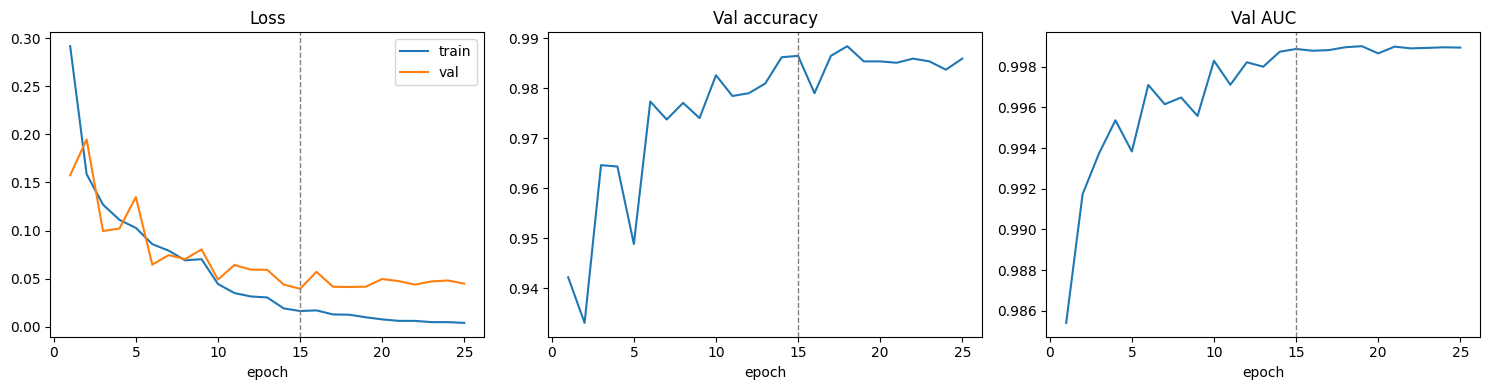

In [ ]:
h = pd.DataFrame(state["history"])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("Loss")
ax[1].plot(h.epoch, h.val_acc); ax[1].set_title("Val accuracy")
ax[2].plot(h.epoch, h.val_auc); ax[2].set_title("Val AUC")
for a in ax:
    a.axvline(state["best_epoch"], color="gray", ls="--", lw=1); a.set_xlabel("epoch")
ax[0].legend(); plt.tight_layout()
plt.savefig(RUN_DIR / "curves.png", dpi=300); plt.show()

## 10. Kiểm tra trên tập test

Dùng checkpoint **tốt nhất theo val** (`best.pt`). 
Quy ước: lớp dương = `covid19`; sensitivity = recall của covid19, specificity = recall của normal.

Nạp best.pt: epoch 15, val_loss = 0.0395
              precision    recall  f1-score   support

      normal     0.9819    0.9911    0.9865      2140
     covid19     0.9920    0.9837    0.9878      2395

    accuracy                         0.9872      4535
   macro avg     0.9870    0.9874    0.9872      4535
weighted avg     0.9873    0.9872    0.9872      4535

{'accuracy': 0.9872, 'auc': np.float64(0.9987), 'f1': 0.9878, 'loss': 0.0439, 'sensitivity': np.float64(0.9837), 'specificity': np.float64(0.9911)}


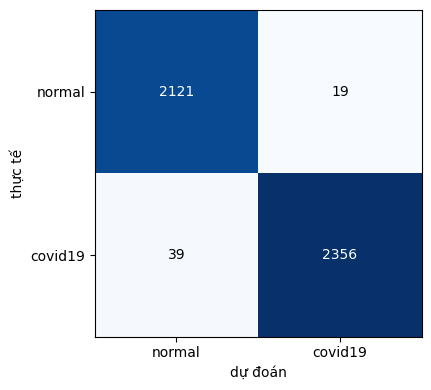

In [ ]:
def run_test(model, out_dir, tag="test"):
    r = evaluate(model, test_dl)
    cm = confusion_matrix(r["labels"], r["pred"])
    tn, fp, fn, tp = cm.ravel()
    metrics = dict(accuracy=r["acc"], auc=r["auc"], f1=r["f1"], loss=r["loss"],
                   sensitivity=tp / (tp + fn), specificity=tn / (tn + fp), n=int(len(r["labels"])),
                   confusion_matrix=cm.tolist(), label_names=label_names)
    print(classification_report(r["labels"], r["pred"], target_names=label_names, digits=4))
    print({k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)})

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(label_names); ax.set_yticks([0, 1]); ax.set_yticklabels(label_names)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("thực tế")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout(); plt.savefig(Path(out_dir) / f"{tag}_confusion_matrix.png", dpi=300); plt.show()
    (Path(out_dir) / f"{tag}_metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False))
    return metrics

best_ckpt = torch.load(RUN_DIR / "best.pt", map_location="cpu", weights_only=False)
print(f"Nạp best.pt: epoch {best_ckpt['epoch']}, {best_ckpt['monitor']} = {best_ckpt['value']:.4f}")
model = build_model().to(device)
model.load_state_dict(best_ckpt["model"])
test_metrics = run_test(model, RUN_DIR)

## 11. Đẩy kết quả test và model card lên Hub

In [18]:
upload_run_dir(f"test results {RUN_NAME}")
print(f"Xong: https://huggingface.co/{MODEL_REPO_ID}/tree/main/{RUNS_PREFIX}/{RUN_NAME}")

Xong: https://huggingface.co/dacntt-kltn/densenet121-covid-normal-cxr


## 12. Test lại một checkpoint bất kỳ trên Hub

Dùng ở phiên khác, không cần train lại. Để trống `HF_CHECKPOINT_FILENAME` thì lấy `best.pt` của run mới nhất.
Ví dụ: `training-runs/00000-densenet121-covid-normal/best.pt`

Dùng checkpoint: training-runs/00000-densenet121-covid-normal/best.pt
              precision    recall  f1-score   support

      normal     0.9958    0.9963    0.9960      2140
     covid19     0.9967    0.9962    0.9965      2395

    accuracy                         0.9963      4535
   macro avg     0.9962    0.9963    0.9962      4535
weighted avg     0.9963    0.9963    0.9963      4535

{'accuracy': 0.9963, 'auc': np.float64(0.9998), 'f1': 0.9965, 'loss': 0.0167, 'sensitivity': np.float64(0.9962), 'specificity': np.float64(0.9963)}


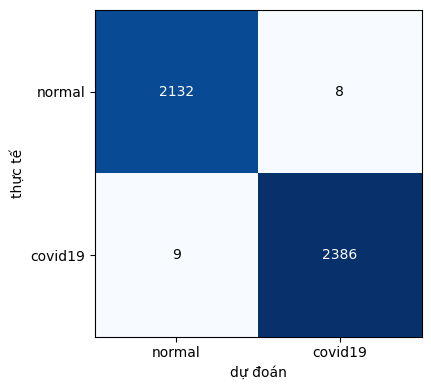

In [19]:
HF_CHECKPOINT_FILENAME = "training-runs/00000-densenet121-covid-normal/best.pt"

if not HF_CHECKPOINT_FILENAME:
    files = list_repo_files(MODEL_REPO_ID, repo_type="model")
    bests = sorted(f for f in files if f.startswith(f"{RUNS_PREFIX}/") and f.endswith("/best.pt"))
    HF_CHECKPOINT_FILENAME = bests[-1]
print("Dùng checkpoint:", HF_CHECKPOINT_FILENAME)

p = hf_hub_download(MODEL_REPO_ID, HF_CHECKPOINT_FILENAME, repo_type="model")
ck = torch.load(p, map_location="cpu", weights_only=False)
m = densenet121(weights=None)
m.classifier = nn.Linear(m.classifier.in_features, 1)
m.load_state_dict(ck["model"]); m = m.to(device)
Path("/kaggle/working/hub_test").mkdir(exist_ok=True)
_ = run_test(m, "/kaggle/working/hub_test", tag="hub_ckpt")